In [2]:
! python -m pip install gurobipy
! python -m pip install networkx
! python -m pip install matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.3/14.3 MB 58.4 MB/s eta 0:00:00


In [4]:
import gurobipy as gp
from gurobipy import GRB
import networkx as nx
import matplotlib.pyplot as plt

# Grafo
G = nx.DiGraph()
G.add_nodes_from(["A", "B", "C", "D", "E", "F"])

edges = [
    ("A","B", 7, 20), ("A","C", 8, 50),
    ("B","C",-1, 40), ("B","D", 4, 30), ("B","E", 1, 20), ("B","F", 5, 14),
    ("C","F", 3, 48),
    ("D","F", 1, 33),
    ("E","C",-2, 21), ("E","D", 0, 14),
    ("F","E", 3, 18),
]

for i, j, cost, cap in edges:
    G.add_edge(i, j, cost=cost, cap=cap)

# b
b = {n: 0 for n in G.nodes}
b.update({"A": -1, "F": 1})

# budget
BUDGET = 500

# Modello
m = gp.Model("maxf")

# Variabili
x = m.addVars(G.edges, vtype=GRB.INTEGER, lb=0, name="x")

# Variabile maxf
maxf = m.addVar(vtype=GRB.CONTINUOUS, lb=0.0, name="maxf")

# Vincoli bilanciamento: inflow - outflow = b[v] * maxf
for v in G.nodes:
    inflow  = gp.quicksum(x[i, v] for i in G.predecessors(v))
    outflow = gp.quicksum(x[v, j] for j in G.successors(v))
    m.addConstr(inflow - outflow == b[v] * maxf, name=f"balance[{v}]")

# Vincoli capacità
for (i, j) in G.edges:
    m.addConstr(x[i, j] <= G[i][j]["cap"], name=f"capacity[{i},{j}]")

# Vincolo budget
m.addConstr(gp.quicksum(G[i][j]["cost"] * x[i, j] for (i, j) in G.edges) <= BUDGET,
            name="budget_limitation")

# O.f.
m.setObjective(maxf, GRB.MAXIMIZE)


# Ottimizza
m.optimize()

# Risultati
archi_con_flusso = []
if m.status == GRB.OPTIMAL:
    print(f"maxf = {maxf.X:.6g}")
    print("\nFlussi sugli archi (x[i,j] > 0):")
    for (i, j) in G.edges:
        if x[i, j].X > 1e-9:
            archi_con_flusso.append((i, j))
            print(f"  x[{i},{j}] = {x[i,j].X:.6g}")

    used_budget = sum(G[i][j]["cost"] * x[i, j].X for (i, j) in G.edges)
    print(f"\nBudget usato: {used_budget:.6g} / {BUDGET}")



Restricted license - for non-production use only - expires 2026-11-23
Gurobi Optimizer version 12.0.3 build v12.0.3rc0 (linux64 - "Ubuntu 22.04.4 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Optimize a model with 18 rows, 12 columns and 45 nonzeros
Model fingerprint: 0x89fcb12f
Variable types: 1 continuous, 11 integer (0 binary)
Coefficient statistics:
  Matrix range     [1e+00, 8e+00]
  Objective range  [1e+00, 1e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [1e+01, 5e+02]
Found heuristic solution: objective -0.0000000
Presolve removed 12 rows and 1 columns
Presolve time: 0.00s
Presolved: 6 rows, 11 columns, 30 nonzeros
Variable types: 0 continuous, 11 integer (0 binary)

Root relaxation: objective 4.909091e+01, 4 iterations, 0.00 seconds (0.00 work units)

    Nodes    |    Current Node    |     Objective Bounds      |     Work
 Expl Unexpl |  Obj  Depth IntIn

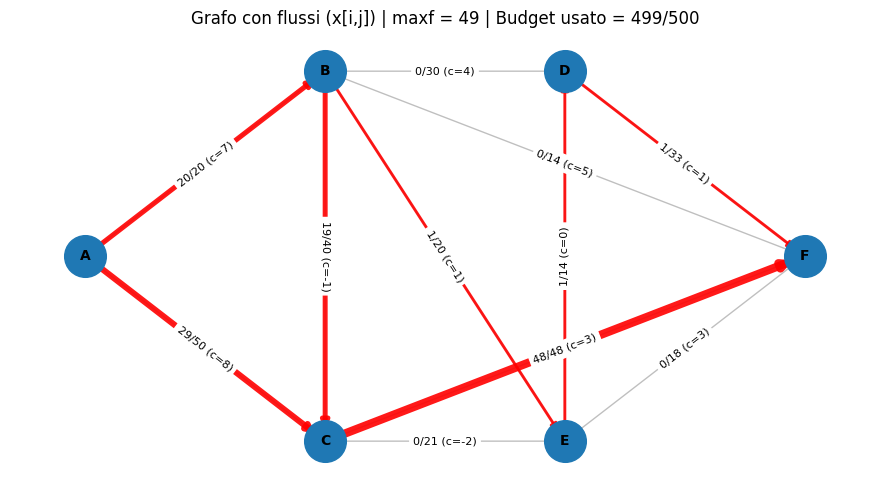

In [6]:
# Visualizzazione
pos = {
    "A": (0, 2),
    "B": (1.5, 3),
    "C": (1.5, 1),
    "D": (3, 3),
    "E": (3, 1),
    "F": (4.5, 2),
}

plt.figure(figsize=(9, 5))

nx.draw_networkx_edges(G, pos, edgelist=list(G.edges), width=1.0, alpha=0.25, arrows=True)

if archi_con_flusso:
    flows = [x[i, j].X for (i, j) in archi_con_flusso]
    fmax = max(flows) if flows else 1.0
    widths = [2.0 + 4.0 * (x[i, j].X / fmax) for (i, j) in archi_con_flusso]
    nx.draw_networkx_edges(G, pos, edgelist=archi_con_flusso, width=widths, alpha=0.9, arrows=True, edge_color="r")

nx.draw_networkx_nodes(G, pos, node_size=900)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold")

edge_labels = {}
for (i, j) in G.edges:
    flow = x[i, j].X if m.status == GRB.OPTIMAL else 0.0
    cap = G[i][j]["cap"]
    cost = G[i][j]["cost"]
    if flow > 1e-9:
        edge_labels[(i, j)] = f"{flow:.0f}/{cap} (c={cost})"
    else:
        edge_labels[(i, j)] = f"0/{cap} (c={cost})"
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

title = "Grafo con flussi (x[i,j])"
if m.status == GRB.OPTIMAL:
    title += f" | maxf = {maxf.X:.3g} | Budget usato = {used_budget:.3g}/{BUDGET}"
plt.title(title)
plt.axis("off")
plt.tight_layout()
plt.show()